# Branch Cash Demand Forecasting: walkthrough

Branches that hold too much cash pay for idle money and insurance. Branches that hold too little turn customers away. Treasury needs a **per-branch, per-currency forecast** tied to **what is actually in the vault**.

*Synthetic data. The production system ran on a bank's teller and general-ledger data across NGN, USD, GBP and EUR.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("cmdstanpy").disabled = True
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True, capture_output=True)
from src.pipeline import connect, run_staging
con = connect()
display(con.execute("SELECT * FROM gl_vault_legacy LIMIT 3").df())
display(con.execute("SELECT * FROM gl_vault_acquired LIMIT 3").df())

,BRANCH_CODE,GL_DATE,CCY_CODE,GL_ACCT,CLOSING_BAL
0,B100,2024-01-02,NGN,VAULT_CASH,2.672727e+08
1,B100,2024-01-03,NGN,VAULT_CASH,2.516707e+08
2,B100,2024-01-04,NGN,VAULT_CASH,2.562584e+08


,sol_id,value_date,crncy_num,gl_sub_head,eod_balance
0,S113,2024-01-02,566,10101,4.138745e+08
1,S113,2024-01-03,566,10101,4.185826e+08
2,S113,2024-01-04,566,10101,4.106788e+08


## 1. Two ledgers, one truth
After a merger, legacy and acquired branches post vault cash to **different GL tables with different schemas**: different column names, branch-code formats, and alphabetic vs ISO-numeric currency codes. `stg_01` harmonises and unions them.

## 2. Sequential staging (and why)
In production, one long query over the GL history kept failing with Oracle's **ORA-01555 "snapshot too old"**. Splitting it into short, materialised stages fixed this:

`stg_01_vault_unified` → `stg_02_opening_balance` (LAG) → `stg_03_customer_flow` → `stg_04_cash_position`

In [2]:
pos = run_staging(con)
pos[pos.branch_code == "B100"].head(8)

,branch_code,currency,bal_date,gl_source,vault_opening,deposits,withdrawals,net_outflow,vault_closing,implied_cit
0,B100,EUR,2024-01-03,LEGACY,43203.70,9692.66,7778.63,-1914.03,45117.73,6.366463e-12
1,B100,EUR,2024-01-04,LEGACY,45117.73,9140.82,9175.29,34.47,45083.26,0.000000e+00
2,B100,EUR,2024-01-05,LEGACY,45083.26,13523.39,11115.40,-2407.99,47491.25,-1.818989e-12
3,B100,EUR,2024-01-08,LEGACY,47491.25,10043.90,8996.41,-1047.49,48538.74,-1.818989e-12
4,B100,EUR,2024-01-09,LEGACY,48538.74,9451.40,5894.05,-3557.35,52096.10,1.000000e-02
5,B100,EUR,2024-01-10,LEGACY,52096.10,10378.47,7456.19,-2922.28,55018.38,-9.094947e-13
6,B100,EUR,2024-01-11,LEGACY,55018.38,6935.05,8120.03,1184.98,53833.40,3.637979e-12
7,B100,EUR,2024-01-12,LEGACY,53833.40,12134.40,9478.61,-2655.79,56489.19,1.818989e-12


## 3. Recovering cash-in-transit
The teller system only records customer cash. Replenishments and evacuations by cash-in-transit vans only show up as jumps in the vault. So:

`implied_cit = closing − opening + net_customer_outflow`

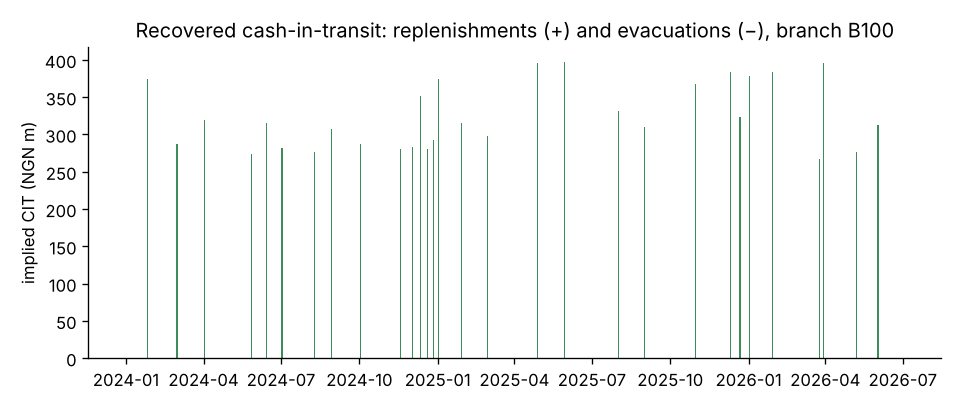

In [3]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
display(Image("reports/figures/implied_cit_B100.png", width=700))

## 4. Forecast demand, not logistics
**Design decision:** Prophet forecasts **net customer flow only**. CIT is an operational decision, not demand, so it is added back by a deterministic position-reconstruction layer. The model captures weekly cycles, month-end salary peaks, the December festive season and Nigerian public holidays (with a rush before and catch-up after).

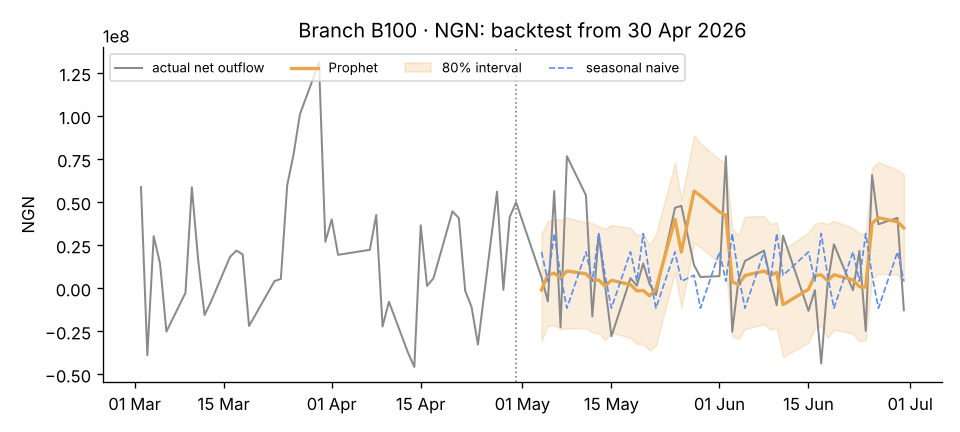

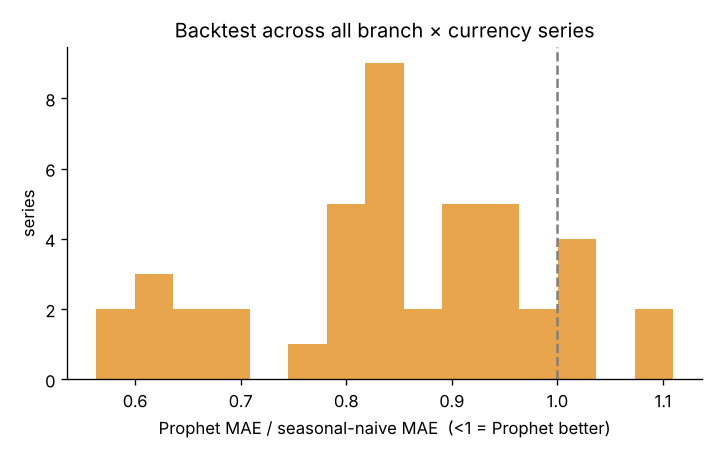

86% of 44 series beat the seasonal-naive benchmark; median MAE improvement 15%


,currency,series,rel_mae_median,coverage,position_err
0,EUR,8,0.934,0.756,0.096
1,GBP,8,0.919,0.691,0.071
2,NGN,20,0.776,0.768,0.103
3,USD,8,0.903,0.753,0.113


In [4]:
display(Image("reports/figures/backtest_B100_NGN.png", width=720))
display(Image("reports/figures/relative_mae.png", width=480))
m = json.load(open("reports/metrics.json"))
print(f"{m['share_series_beating_naive']:.0%} of {m['series']} series beat the seasonal-naive benchmark; median MAE improvement {m['median_mae_improvement_vs_naive']:.0%}")
pd.DataFrame(m["by_currency"])

NGN gains the most because its patterns (salary month-end, festive season) are strong and regular. FX flows are lumpier and closer to noise.

## 5. From forecast to action
The forecast is projected forward from the 30 June closing balance. Any vault expected to fall below its 10th-percentile level within 5 business days is flagged for replenishment.

In [5]:
pd.read_csv('reports/replenishment_outlook.csv').head(10)

,branch_code,currency,closing_30jun,projected_day10,floor_p10,breach_in_business_days,action
0,B100,EUR,6.514250e+04,6.626739e+04,3.999286e+04,NaN,OK
1,B100,GBP,7.135495e+04,6.728247e+04,4.776988e+04,NaN,OK
2,B100,NGN,3.292722e+08,3.059909e+08,2.193088e+08,NaN,OK
3,B100,USD,2.653078e+05,2.582862e+05,1.856242e+05,NaN,OK
4,B101,EUR,4.107240e+04,3.979673e+04,1.996950e+04,NaN,OK
5,B101,GBP,3.111951e+04,2.740281e+04,2.332270e+04,NaN,OK
6,B101,USD,1.636099e+05,1.816009e+05,9.855722e+04,NaN,OK
7,B102,EUR,9.251966e+04,9.251971e+04,3.970046e+04,NaN,OK
8,B102,GBP,7.653870e+04,8.168210e+04,5.403943e+04,NaN,OK
9,B102,USD,3.061572e+05,3.558413e+05,2.319177e+05,NaN,OK
